# 02 · Major-outage classifier

**Lights Out: Predicting Storm-Driven Power Outages and Recovery Across U.S. Counties**

Second step of our Option A analysis. The question: **when a storm hits a county, will more than 10% of its
customers lose power at the peak?** (`peak_share_out > 0.10`, the *major outage* label defined in
`01_eda.ipynb`).

Plan:

1. Build the modelling table and the label.
2. Choose features that are known **before or when the storm hits** (no leakage).
3. Decide how to evaluate: cross-validation **split by storm**, and why a random split is misleading.
4. Start from very simple baselines, then compare five scikit-learn models.
5. Tune the two best models a little, then test once on storms the models have never seen.
6. Look at what the model relies on.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

DATA = Path('..') / 'data'
FIG = Path('..') / 'figures'
SEED = 0
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (9, 4)

## 1. Modelling table and label

We start from `utility_by_county.csv` (one row per storm and county, with the reported outages) and add:

- from `storms.csv`: storm type (`kind`), year and month (landfall date, or first impact date);
- from `county_summary.csv`: whether the county is inside the NHC 34-knot wind radius, and the median
  night-light radiance **before** the storm (`baseline_radiance`, a rough proxy for how urban the county is).

As seen in `01_eda.ipynb`, rows with `reason != 'ok'` have no outage data, and `peak_share_out` is empty for
246 rows where more customers were reported out than the estimated customer count. Both are dropped.

In [2]:
storms = pd.read_csv(DATA / 'storms.csv')
utility = pd.read_csv(DATA / 'utility_by_county.csv', low_memory=False)
county = pd.read_csv(DATA / 'county_summary.csv', low_memory=False,
                     usecols=['event_id', 'geoid', 'in_nhc_wind_radius', 'baseline_radiance', 'outage_min_ratio'])

storms['date'] = pd.to_datetime(storms['landfall'].fillna(storms['first_impact_date']), errors='coerce')
storms['year'] = storms['date'].dt.year
storms['month'] = storms['date'].dt.month

df = (utility.merge(storms[['event_id', 'name', 'kind', 'year', 'month']], on='event_id', how='left')
             .merge(county, on=['event_id', 'geoid'], how='left'))
print('rows after the joins:', len(df), '(same as utility_by_county:', len(utility), ')')

df = df[(df['reason'] == 'ok') & df['peak_share_out'].notna()].copy()
df['major_outage'] = (df['peak_share_out'] > 0.10).astype(int)
print(f"usable rows: {len(df):,} from {df['event_id'].nunique()} storms")
print(f"major outages: {df['major_outage'].mean():.1%}")

rows after the joins: 11686 (same as utility_by_county: 11686 )
usable rows: 9,989 from 462 storms
major outages: 49.6%


## 2. Features

A useful model must work **at the time of the storm**, before the utilities report anything. So we only keep
information that is known before or when the storm hits:

| Feature | Type | Source |
|---|---|---|
| `kind` (storm type) | categorical | storms.csv |
| `state` | categorical | utility_by_county.csv |
| `wind_radius` (inside / outside the NHC wind radius, or unknown) | categorical | county_summary.csv |
| `year`, `month` | numeric | storms.csv |
| `log_customers` = log(1 + `customers_total`), county size | numeric | utility_by_county.csv |
| `log_baseline` = log(1 + `baseline_radiance`), pre-storm night light | numeric | county_summary.csv |

Everything measured **after** the storm is left out on purpose: `peak_customers_out`, `customer_hours_out`,
the restoration times, and the night-light drop (`outage_min_ratio`). They would leak the answer, or describe the
outage instead of predicting it. The night-light drop is only used as a separate baseline in section 4.

The wind radius only exists for the Atlantic storms covered by HURDAT2. Elsewhere it is empty, and empty does
**not** mean outside (see `data/DATA_DICTIONARY.md`), so we keep it as a third category, `unknown`.

In [3]:
df['log_customers'] = np.log1p(df['customers_total'])
df['log_baseline'] = np.log1p(df['baseline_radiance'])
df['wind_radius'] = (df['in_nhc_wind_radius'].astype('string').str.lower()
                       .map({'true': 'inside', 'false': 'outside'}).fillna('unknown'))

CAT = ['kind', 'state', 'wind_radius']
NUM = ['year', 'month', 'log_customers', 'log_baseline']
X = df[CAT + NUM]
y = df['major_outage'].to_numpy()
groups = df['event_id'].to_numpy()

print(df['wind_radius'].value_counts().to_string(), end='\n\n')
print('missing values per feature:')
print(X.isna().sum().to_string())

wind_radius
unknown    6228
outside    2082
inside     1679

missing values per feature:
kind             0
state            0
wind_radius      0
year             0
month            0
log_customers    0
log_baseline     0


## 3. How to evaluate: split by storm

All counties hit by the same storm share the same weather, the same date and often the same utility. If counties
of one storm end up both in the training set and in the test set, the model can recognise the storm instead of
learning something general. This is **leakage**, and it makes the score look better than it really is.

So every evaluation below uses `GroupKFold` with the storm (`event_id`) as the group: a storm is either fully in the
training folds or fully in the test fold. The metric is the **ROC AUC** (0.5 = coin flip, 1 = perfect), which
does not depend on a decision threshold. The two classes have similar sizes (about 50/50), so accuracy is also
meaningful, and we report it at the end.

We first keep 20% of the storms aside as a **final test set**, used only once in section 6.

In [4]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]

print(f'train: {len(train_idx):,} rows, {len(set(g_train))} storms, {y_train.mean():.1%} major')
print(f'test : {len(test_idx):,} rows, {len(set(groups[test_idx]))} storms, {y_test.mean():.1%} major')
print('storms in both sets:', len(set(g_train) & set(groups[test_idx])))

cv = GroupKFold(n_splits=5)

train: 7,998 rows, 369 storms, 50.0% major
test : 1,991 rows, 93 storms, 47.8% major
storms in both sets: 0


## 4. Simple baselines

Before any machine learning, three very simple predictors tell us what "good" means:

1. **Constant**: always predict the same thing. AUC 0.5 by definition.
2. **Storm-type lookup table**: predict the share of major outages seen for that storm type in the training folds.
3. **Night light only**: no training at all, just use how dark the county got after the storm
   (`outage_min_ratio`, lower = darker). This is the question from our proposal: can satellites alone detect an outage?

In [5]:
def lookup_auc(X_, y_, g_):
    scores = []
    for tr, te in cv.split(X_, y_, g_):
        rate = pd.Series(y_[tr]).groupby(X_['kind'].to_numpy()[tr]).mean()
        pred = pd.Series(X_['kind'].to_numpy()[te]).map(rate).fillna(y_[tr].mean())
        scores.append(roc_auc_score(y_[te], pred))
    return np.array(scores)

nl = df.iloc[train_idx]['outage_min_ratio']
has_nl = nl.notna().to_numpy()

baselines = {
    'Constant': np.array([0.5]),
    'Storm-type lookup table': lookup_auc(X_train, y_train, g_train),
    'Night light only (no model)': np.array([roc_auc_score(y_train[has_nl], -nl[has_nl])]),
}
for name, s in baselines.items():
    print(f'{name:30s} AUC {s.mean():.3f}')
print(f'\n(night light exists for {has_nl.sum():,} of {len(has_nl):,} training rows)')

Constant                       AUC 0.500
Storm-type lookup table        AUC 0.607
Night light only (no model)    AUC 0.563

(night light exists for 5,860 of 7,998 training rows)


The night-light signal is weak, close to the AUC of 0.52 to 0.57 reported by the dataset authors
(`data/validation_pooled.csv`). Clouds, generators that switch the lights back on before the grid, and destroyed
buildings that stay dark all blur the signal (`data/LIMITS.md`). The storm type alone does a bit better.

## 5. Comparing five models

We compare five classic scikit-learn classifiers, from the simplest to the strongest on tabular data:

| Model | Why we try it |
|---|---|
| Logistic regression | Linear baseline promised in our proposal, readable coefficients |
| Gaussian Naive Bayes | Very fast, but assumes the features are independent |
| Decision tree (depth 5) | Can be drawn and explained |
| Random forest | Many trees on random subsets, robust with little tuning |
| Gradient boosting (`HistGradientBoostingClassifier`) | Trees built one after the other to fix the previous errors, the usual best choice for tables |

Linear models and Naive Bayes need numbers, so categories are **one-hot encoded** and numeric features are
**scaled**. There are no missing values in these rows (see the check above), but an imputer (median of the
training folds) is kept in the pipeline so the model would not break on a county without baseline nights.
Gradient boosting handles categories and missing values natively, so it gets an ordinal
encoding instead. Every transformation is inside a `Pipeline`, so it is learned on the training folds only.

In [6]:
def onehot(model, scale=True):
    num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()) if scale else SimpleImputer(strategy='median')
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), CAT),
        ('num', num, NUM)])
    return make_pipeline(pre, model)

def ordinal(model):
    pre = ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
        ('num', 'passthrough', NUM)])
    return make_pipeline(pre, model)

models = {
    'Logistic regression': onehot(LogisticRegression(max_iter=2000)),
    'Naive Bayes': onehot(GaussianNB()),
    'Decision tree (depth 5)': onehot(DecisionTreeClassifier(max_depth=5, random_state=SEED), scale=False),
    'Random forest': onehot(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED), scale=False),
    'Gradient boosting': ordinal(HistGradientBoostingClassifier(categorical_features=[0, 1, 2], random_state=SEED)),
}

scores = dict(baselines)
for name, model in models.items():
    scores[name] = cross_val_score(model, X_train, y_train, groups=g_train, cv=cv, scoring='roc_auc', n_jobs=-1)

table = pd.DataFrame({'mean AUC': {k: v.mean() for k, v in scores.items()},
                      'std': {k: v.std() for k, v in scores.items()}}).sort_values('mean AUC')
table.round(3)

,mean AUC,std
Constant,0.500,0.000
Night light only (no model),0.563,0.000
Naive Bayes,0.603,0.048
Storm-type lookup table,0.607,0.070
Decision tree (depth 5),0.678,0.044
Gradient boosting,0.698,0.033
Logistic regression,0.706,0.027
Random forest,0.720,0.030


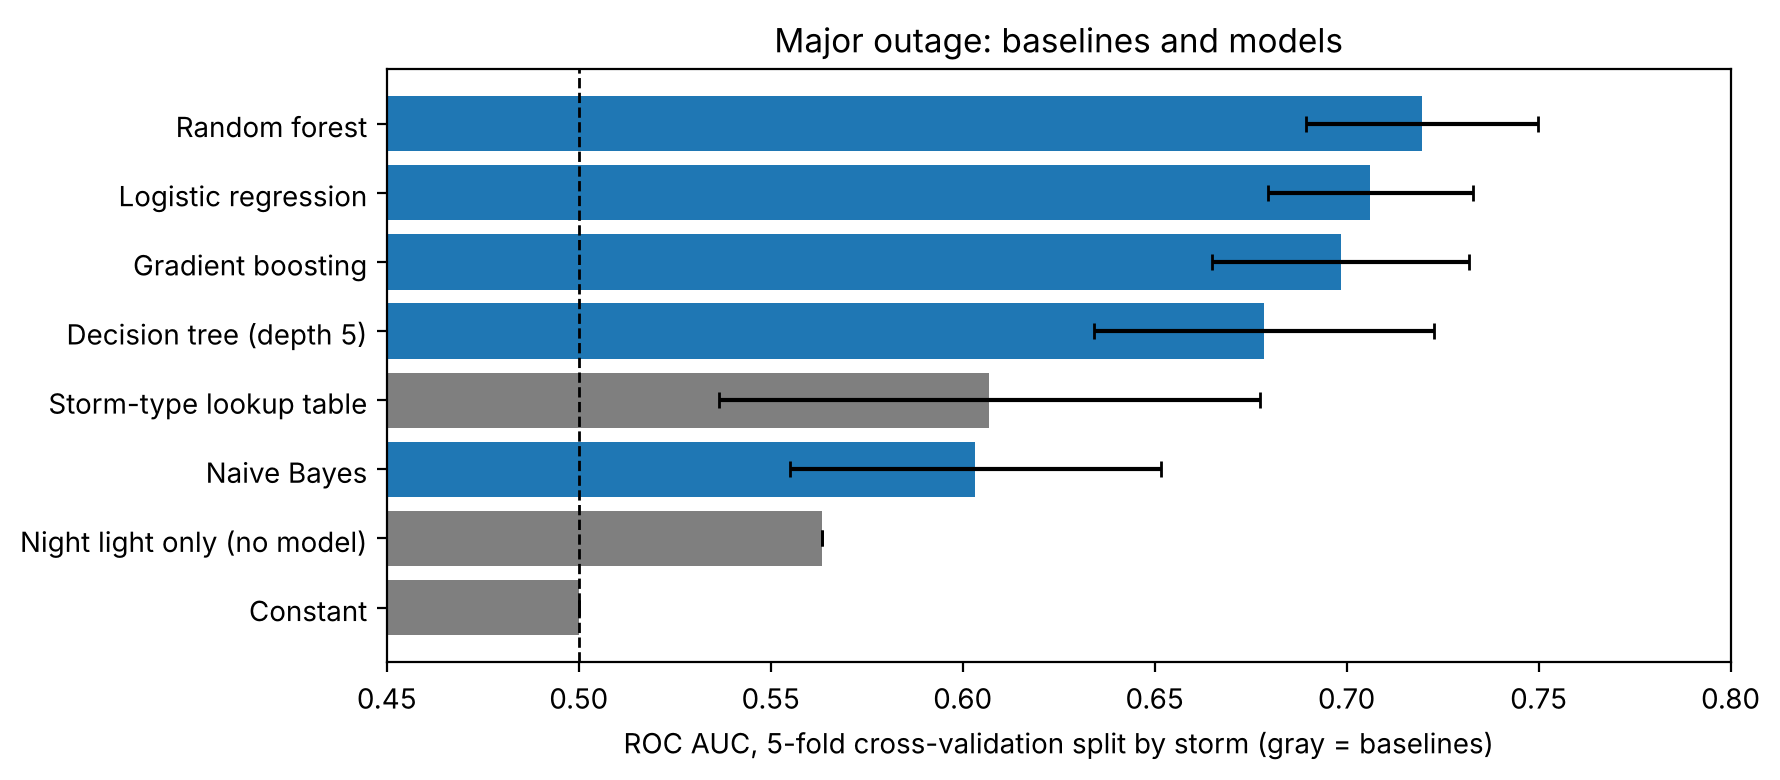

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tab:blue' if k in models else 'tab:gray' for k in table.index]
ax.barh(table.index, table['mean AUC'], xerr=table['std'], color=colors, capsize=3)
ax.axvline(0.5, color='black', ls='--', lw=1)
ax.set_xlim(0.45, 0.8)
ax.set_xlabel('ROC AUC, 5-fold cross-validation split by storm (gray = baselines)')
ax.set_title('Major outage: baselines and models')
plt.tight_layout()
fig.savefig(FIG / 'classifier_models.png', dpi=150, bbox_inches='tight')
plt.show()

### Why the split matters

Same gradient boosting model, two ways of cutting the training data into folds: by storm, or at random.

In [8]:
gb = models['Gradient boosting']
by_storm = scores['Gradient boosting']
random_split = cross_val_score(gb, X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED),
                               scoring='roc_auc', n_jobs=-1)
print(f'split by storm : AUC {by_storm.mean():.3f}')
print(f'random split   : AUC {random_split.mean():.3f}  <- too optimistic')

split by storm : AUC 0.698
random split   : AUC 0.793  <- too optimistic


The random split gives a clearly higher score, but this score would not hold for a new storm: the model has
already seen other counties of the same storm. From now on we only trust the split by storm.

## 6. A little tuning, then the final test

Random forest is the best model, and logistic regression and gradient boosting are close behind. The two tree
ensembles have settings that change their behaviour a lot (tree size, learning rate, regularisation), so we tune
those two. We try a few settings for each, still with the split by storm on the training storms only. The grids are small on purpose: the goal is to show the procedure, not to squeeze the last point.

In [9]:
from sklearn.model_selection import GridSearchCV

searches = {
    'Random forest': GridSearchCV(
        onehot(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), scale=False),
        {'randomforestclassifier__min_samples_leaf': [1, 5, 20],
         'randomforestclassifier__max_features': ['sqrt', 0.5]},
        cv=cv, scoring='roc_auc', n_jobs=-1),
    'Gradient boosting': GridSearchCV(
        ordinal(HistGradientBoostingClassifier(categorical_features=[0, 1, 2], random_state=SEED)),
        {'histgradientboostingclassifier__learning_rate': [0.03, 0.1],
         'histgradientboostingclassifier__max_leaf_nodes': [15, 31],
         'histgradientboostingclassifier__l2_regularization': [0.0, 1.0]},
        cv=cv, scoring='roc_auc', n_jobs=-1),
}
for name, search in searches.items():
    search.fit(X_train, y_train, groups=g_train)
    print(f'{name:18s} best CV AUC {search.best_score_:.3f} with {search.best_params_}')

Random forest      best CV AUC 0.721 with {'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 20}


Gradient boosting  best CV AUC 0.706 with {'histgradientboostingclassifier__l2_regularization': 0.0, 'histgradientboostingclassifier__learning_rate': 0.1, 'histgradientboostingclassifier__max_leaf_nodes': 15}


We keep the model with the best cross-validated AUC, refit it on all training storms (`GridSearchCV` does this
automatically) and evaluate it **once** on the 20% of storms kept aside since section 3.

In [10]:
best_name = max(searches, key=lambda k: searches[k].best_score_)
best = searches[best_name].best_estimator_
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f'final model: {best_name}')
print(f'test AUC      : {roc_auc_score(y_test, proba):.3f}')
print(f'test accuracy : {accuracy_score(y_test, pred):.3f}  (always predicting the majority class: {max(y_test.mean(), 1 - y_test.mean()):.3f})')
print(f'precision     : {precision_score(y_test, pred):.3f}')
print(f'recall        : {recall_score(y_test, pred):.3f}')
print(f'F1            : {f1_score(y_test, pred):.3f}')

final model: Random forest
test AUC      : 0.707
test accuracy : 0.668  (always predicting the majority class: 0.522)
precision     : 0.637
recall        : 0.708
F1            : 0.671


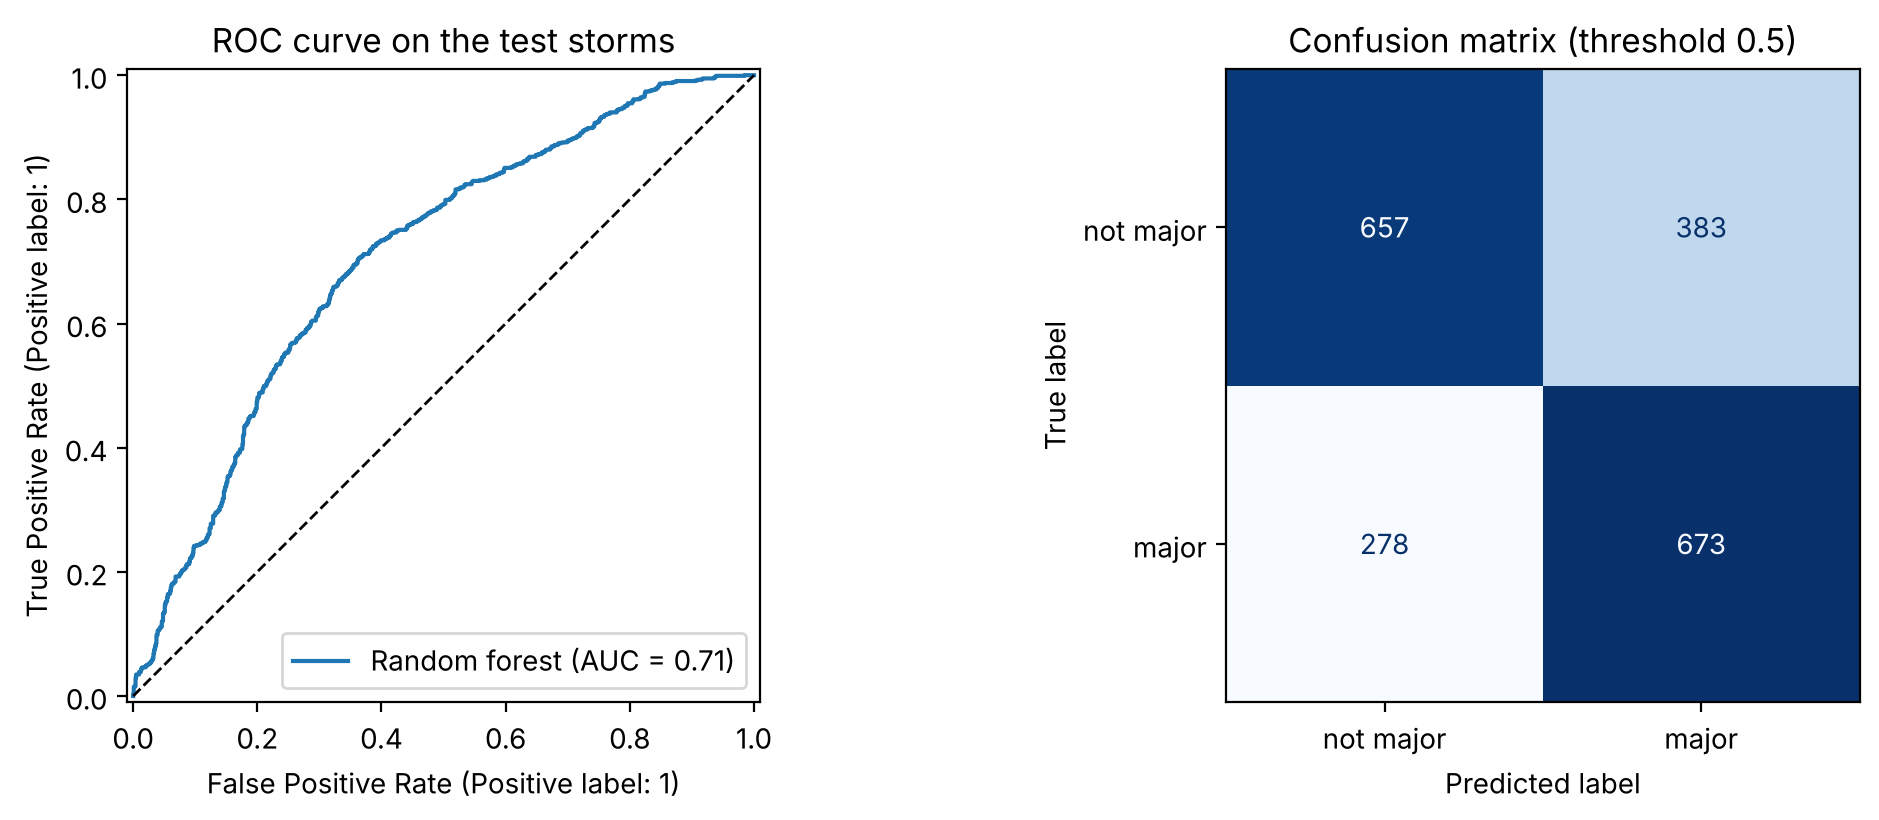

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC curve on the test storms')
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['not major', 'major'], ax=axes[1],
                                        colorbar=False, cmap='Blues')
axes[1].set_title('Confusion matrix (threshold 0.5)')
plt.tight_layout()
fig.savefig(FIG / 'classifier_test.png', dpi=150, bbox_inches='tight')
plt.show()

## 6b. A closer look at the test results

Three checks on the final model, without training anything new: how stable the cross-validation score is and how
it compares with the test, which decision threshold to use, and which storms the model gets wrong.

### Cross-validation vs test

Mean ± standard deviation of the AUC over the 5 storm folds, next to the AUC on the 93 test storms.

In [12]:
best_search = searches[best_name]
i_best = best_search.best_index_
fold_aucs = np.array([best_search.cv_results_[f'split{k}_test_score'][i_best] for k in range(cv.get_n_splits())])
print('AUC per fold (tuned ' + best_name + '):', np.round(fold_aucs, 3))

cv_vs_test = pd.DataFrame({
    'CV AUC (mean ± std)': {k: f'{v.mean():.3f} ± {v.std():.3f}' for k, v in scores.items() if k != 'Constant'},
})
cv_vs_test.loc[f'{best_name} (tuned)', 'CV AUC (mean ± std)'] = f'{fold_aucs.mean():.3f} ± {fold_aucs.std():.3f}'
cv_vs_test['test AUC (93 storms)'] = ''
cv_vs_test.loc[f'{best_name} (tuned)', 'test AUC (93 storms)'] = f'{roc_auc_score(y_test, proba):.3f}'
nl_test = df.iloc[test_idx]['outage_min_ratio']
has_nl_test = nl_test.notna().to_numpy()
cv_vs_test.loc['Night light only (no model)', 'test AUC (93 storms)'] = f'{roc_auc_score(y_test[has_nl_test], -nl_test[has_nl_test]):.3f}'
cv_vs_test

AUC per fold (tuned Random forest): [0.678 0.714 0.741 0.703 0.77 ]


,CV AUC (mean ± std),test AUC (93 storms)
Storm-type lookup table,0.607 ± 0.070,
Night light only (no model),0.563 ± 0.000,0.600
Logistic regression,0.706 ± 0.027,
Naive Bayes,0.603 ± 0.048,
Decision tree (depth 5),0.678 ± 0.044,
Random forest,0.720 ± 0.030,
Gradient boosting,0.698 ± 0.033,
Random forest (tuned),0.721 ± 0.032,0.707


### Which threshold?

The model gives a probability; the label depends on the threshold. Missing a major outage (no crews sent) costs
more than a false alarm (crews on standby for nothing), so a threshold below 0.5 can make sense. The table shows the
trade-off on the test storms. It is shown for illustration only: the threshold is **not** tuned on the test set, and
all other results keep 0.5.

In [13]:
rows = []
for t in [0.3, 0.4, 0.5]:
    p_t = (proba >= t).astype(int)
    tp = int(((p_t == 1) & (y_test == 1)).sum()); fp = int(((p_t == 1) & (y_test == 0)).sum())
    fn = int(((p_t == 0) & (y_test == 1)).sum())
    rows.append({'threshold': t, 'precision': precision_score(y_test, p_t), 'recall': recall_score(y_test, p_t),
                 'F1': f1_score(y_test, p_t), 'major outages found': f'{tp} of {tp + fn}',
                 'missed': fn, 'false alarms': fp})
thresholds = pd.DataFrame(rows).set_index('threshold')
thresholds.round(3)

,precision,recall,F1,major outages found,missed,false alarms
threshold,,,,,,
0.3,0.521,0.958,0.675,911 of 951,40,836
0.4,0.564,0.848,0.678,806 of 951,145,622
0.5,0.637,0.708,0.671,673 of 951,278,383


### Errors per storm

All counties of a storm share the weather, so the model tends to be right or wrong for a whole storm at once. For each
test storm with at least 5 major outages, we compute the recall (share of its major outages that the model found at
threshold 0.5).

In [14]:
test_df = df.iloc[test_idx].assign(proba=proba, pred=pred)
per_storm = (test_df.groupby(['event_id', 'name', 'kind'])
                    .agg(counties=('major_outage', 'size'), major=('major_outage', 'sum'),
                         found=('pred', lambda s: int((s & test_df.loc[s.index, 'major_outage']).sum())),
                         wind_radius=('wind_radius', 'first'), median_share_out=('peak_share_out', 'median'),
                         mean_proba=('proba', 'mean'))
                    .reset_index())
per_storm['recall'] = per_storm['found'] / per_storm['major']
big = per_storm[per_storm['major'] >= 5].sort_values('recall')
print(f"test storms with at least 5 major outages: {len(big)} (of {per_storm['event_id'].nunique()})")
print(f"recall per storm: median {big['recall'].median():.2f}, "
      f"{(big['recall'] < 0.5).sum()} storms below 0.5, {(big['recall'] >= 0.9).sum()} storms at 0.9 or more")
big['name'] = big['name'].str.slice(0, 40)
display(big.head(5).round(2))
big.tail(5).round(2)

test storms with at least 5 major outages: 47 (of 93)
recall per storm: median 0.88, 13 storms below 0.5, 23 storms at 0.9 or more


,event_id,name,kind,counties,major,found,wind_radius,median_share_out,mean_proba,recall
23,DR-4317,"Severe Storms, Tornadoes, Straight-Line",flood,44,11,0,unknown,0.04,0.32,0.0
30,DR-4375,Severe Winter Storm And Straight-Line Wi,snowstorm,9,6,0,unknown,0.15,0.43,0.0
37,DR-4416,Severe Storms And Flooding,flood,36,8,0,unknown,0.04,0.40,0.0
38,DR-4420,"Severe Winter Storm, Straight-Line Winds",flood,32,5,0,unknown,0.01,0.32,0.0
42,DR-4461,Severe Storms And Flooding,flood,28,8,0,unknown,0.05,0.30,0.0


,event_id,name,kind,counties,major,found,wind_radius,median_share_out,mean_proba,recall
85,DR-4861,"Severe Storm, Straight-Line Winds, Flood",severe_storm,12,9,9,unknown,0.16,0.61,1.0
84,DR-4860,"Severe Storms, Straight-Line Winds, Floo",severe_storm,68,36,36,unknown,0.11,0.67,1.0
86,DR-4862,"Severe Storms, Straight-Line Winds, Torn",severe_storm,8,6,6,unknown,0.19,0.61,1.0
87,DR-4864,"Severe Storms, Straight-Line Winds, Torn",severe_storm,90,42,42,unknown,0.10,0.72,1.0
88,DR-4869,"Severe Winter Storm, Straight-Line Winds",severe_storm,26,20,20,unknown,0.28,0.61,1.0


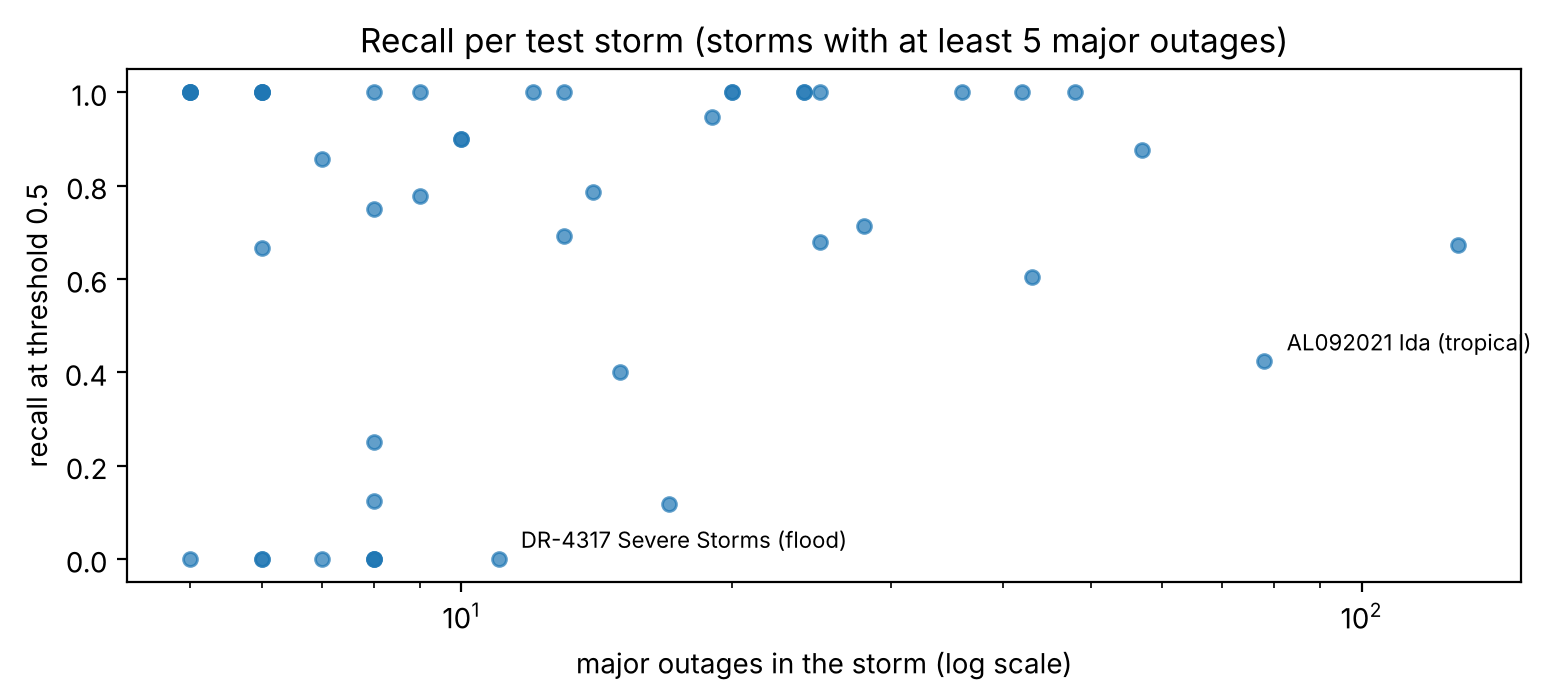

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(big['major'], big['recall'], s=25, alpha=0.7)
worst = big.sort_values(['recall', 'major'], ascending=[True, False]).iloc[0]
most_missed = big.assign(missed=big['major'] - big['found']).sort_values('missed').iloc[-1]
for s in (worst, most_missed):
    ax.annotate(f"{s['event_id']} {s['name'].split(',')[0][:20]} ({s['kind']})", (s['major'], s['recall']),
                xytext=(8, 4), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('major outages in the storm (log scale)')
ax.set_ylabel('recall at threshold 0.5')
ax.set_title('Recall per test storm (storms with at least 5 major outages)')
plt.tight_layout()
fig.savefig(FIG / 'classifier_recall_per_storm.png', dpi=150, bbox_inches='tight')
plt.show()

**What these three checks show:**

- **The test score is consistent with cross-validation.** The tuned random forest scores between 0.678 and 0.770 on
  the 5 storm folds (0.721 ± 0.032), and 0.707 on the test storms, inside that range. The spread between folds is
  large: depending on which storms are held out, the AUC moves by almost 0.1. Night light alone scores 0.600 on the
  test storms (0.563 on the training storms): still far below the model.
- **Threshold.** Going from 0.5 to 0.4 finds 133 more major outages (recall 0.71 → 0.85) for 239 more false alarms,
  so it pays off if a missed major outage costs more than about 1.8 false alarms, which is likely for a utility
  planning crews. At 0.3 the model flags almost everything (recall 0.96, but 836 false alarms out of 1,040 counties
  without a major outage). The F1 score barely changes (0.67 to 0.68), so the choice depends on the cost of each error,
  not on the model. A real threshold would be chosen on the training folds; we keep 0.5 elsewhere.
- **The errors are concentrated on some storms.** Half of the test storms have a recall of 0.88 or more, but 13 of 47
  are below 0.5. By storm type, the recall is 0.88 for severe storms, 0.65 for tropical storms, 0.24 for floods and
  0.07 for snowstorms: 7 of the 8 storms where the model finds no major outage at all are floods. Floods cause major
  outages in only 34% of their counties (`01_eda.ipynb`), so the model learns to predict "not major" for them.
- **The storm with the most missed major outages is Hurricane Ida (2021):** 45 missed out of 78. The model found all
  33 major outages *inside* the NHC wind radius and none of the 45 *outside* it (Mississippi and Louisiana counties
  outside the 34-knot radius, and New Jersey, Pennsylvania and New York, hit by Ida's remnants as flooding). In the
  training storms, only 31% of tropical-storm counties outside the radius have a major outage, against 69% inside, so
  the model relies on the radius. Ida shows its limit: a storm can still cause large outages outside the radius, and
  only wind speed or rainfall data could tell these cases apart.

### Results per storm type

Precision, recall and F1 of the final model for each storm type, on the test storms (threshold 0.5).

In [16]:
def scores_by(group):
    rows = []
    for k, g in test_df.groupby(group):
        rows.append({group: k, 'counties': len(g), 'storms': g['event_id'].nunique(),
                     'major share': g['major_outage'].mean(),
                     'precision': precision_score(g['major_outage'], g['pred'], zero_division=0),
                     'recall': recall_score(g['major_outage'], g['pred'], zero_division=0),
                     'F1': f1_score(g['major_outage'], g['pred'], zero_division=0)})
    return pd.DataFrame(rows).set_index(group).sort_values('counties', ascending=False)

per_kind = scores_by('kind')
per_kind.round(2)

,counties,storms,major share,precision,recall,F1
kind,,,,,,
severe_storm,724,48,0.55,0.62,0.88,0.73
tropical,701,7,0.51,0.65,0.65,0.65
flood,430,32,0.27,0.68,0.24,0.35
severe_ice_storm,75,2,0.71,0.71,1.00,0.83
snowstorm,38,3,0.37,0.50,0.07,0.12
tornado,23,1,0.35,0.47,1.00,0.64


### Top-K: where to send crews first

A utility cannot prepare everywhere. If it pre-positions crews in the counties with the highest predicted risk, how
many of them really have a major outage? Without a model, picking counties at random finds the overall share of major
outages in the test set.

In [17]:
order = np.argsort(-proba)
rows = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    k = int(round(frac * len(order)))
    top = y_test[order[:k]]
    rows.append({'top share of counties': f'{frac:.0%}', 'counties': k, 'major outages among them': int(top.sum()),
                 'hit rate': top.mean(), 'share of all major outages found': top.sum() / y_test.sum()})
top_k = pd.DataFrame(rows).set_index('top share of counties')
print(f'random choice: hit rate {y_test.mean():.3f}')
top_k.round(3)

random choice: hit rate 0.478


,counties,major outages among them,hit rate,share of all major outages found
top share of counties,,,,
5%,100,65,0.650,0.068
10%,199,144,0.724,0.151
20%,398,264,0.663,0.278
30%,597,411,0.688,0.432


## 6c. Is the model only learning the year?

The year is the most important feature (section 7), and the share of major outages rises from about 35% in 2015 to
about 60% in recent years, partly because EAGLE-I covered fewer counties in the early years. A model can use such a
pattern as a *shortcut*: it predicts the date of the data rather than the effect of the storm. Two checks:

1. **Without the year:** the same tuned random forest, trained without `year`, scored on the same storm folds and on the
   same test storms.
2. **Train on the past, test on the future:** train on the storms up to 2022 and test on the storms from 2023 on, with
   and without the year. This is also the real use case: a utility predicts next season from past seasons.

These checks are diagnostics. They do not replace the final model of section 6.

In [18]:
best_params = searches[best_name].best_params_
def tuned_rf(num):
    pipe = make_pipeline(
        ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), CAT),
                           ('num', SimpleImputer(strategy='median'), num)]),
        RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED))
    return pipe.set_params(**best_params)

NUM_NO_YEAR = [c for c in NUM if c != 'year']
rows = []
for label, num in [('with year', NUM), ('without year', NUM_NO_YEAR)]:
    cols = CAT + num
    cv_auc = cross_val_score(tuned_rf(num), X_train[cols], y_train, groups=g_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    m = tuned_rf(num).fit(X_train[cols], y_train)
    rows.append({'features': label, 'CV AUC (mean ± std)': f'{cv_auc.mean():.3f} ± {cv_auc.std():.3f}',
                 'test AUC (93 storms)': roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])})

years = df['year'].to_numpy()
past, future = years <= 2022, years >= 2023
for label, num in [('with year', NUM), ('without year', NUM_NO_YEAR)]:
    cols = CAT + num
    m = tuned_rf(num).fit(X[cols][past], y[past])
    rows.append({'features': label + ', train ≤ 2022 / test ≥ 2023',
                 'CV AUC (mean ± std)': '',
                 'test AUC (93 storms)': np.nan,
                 'future AUC (2023+)': roc_auc_score(y[future], m.predict_proba(X[cols][future])[:, 1])})
year_check = pd.DataFrame(rows).set_index('features')
print(f"temporal split: {past.sum():,} rows / {len(set(groups[past]))} storms up to 2022, "
      f"{future.sum():,} rows / {len(set(groups[future]))} storms from 2023 "
      f"(major share {y[past].mean():.1%} vs {y[future].mean():.1%})")
year_check.round(3)

temporal split: 7,016 rows / 310 storms up to 2022, 2,973 rows / 152 storms from 2023 (major share 46.4% vs 57.0%)


,CV AUC (mean ± std),test AUC (93 storms),future AUC (2023+)
features,,,
with year,0.721 ± 0.032,0.707,NaN
without year,0.695 ± 0.030,0.678,NaN
"with year, train ≤ 2022 / test ≥ 2023",,NaN,0.675
"without year, train ≤ 2022 / test ≥ 2023",,NaN,0.657


**What this shows:**

- **The year helps, but it is not the whole story.** Without the year, the AUC drops by about 0.03 (0.721 → 0.695 in
  cross-validation, 0.707 → 0.678 on the test storms). That is about the size of the spread between folds, and the model
  without the year is still far above the simple baselines (storm-type table 0.607, night light 0.56 to 0.60). So the
  model does use the year as a partial shortcut, but most of what it learns comes from the storm type, the wind radius
  and the county.
- **Predicting the future is a little harder.** Trained on the storms up to 2022 and tested on the storms from 2023 on,
  the model reaches an AUC of 0.675 (0.657 without the year), a bit below the 0.707 of the random storm split. The
  recent years have more major outages (57% against 46%), and a model trained on the past under-estimates them. For a
  real deployment, the model should be retrained every season.
- For the final model we keep the year, but we report this check so that its importance is not read as a weather
  effect.

### Saving the results

The numbers and predictions used in the report are saved in `results/`, so that `04_report_figures.ipynb` can redraw
every figure without training anything.

In [19]:
RES = Path('..') / 'results'
RES.mkdir(exist_ok=True)
table.rename_axis('model').to_csv(RES / 'classifier_cv_summary.csv')
pd.DataFrame({name: s for name, s in scores.items() if len(s) == cv.get_n_splits()}
             ).assign(**{f'{best_name} (tuned)': fold_aucs}).rename_axis('fold').to_csv(RES / 'classifier_cv_auc.csv')
test_df[['event_id', 'name', 'kind', 'state', 'year', 'geoid', 'major_outage', 'proba', 'pred']].to_csv(
    RES / 'classifier_test_predictions.csv', index=False)
thresholds.to_csv(RES / 'classifier_thresholds.csv')
per_storm.to_csv(RES / 'classifier_per_storm.csv', index=False)
per_kind.to_csv(RES / 'classifier_per_kind.csv')
top_k.to_csv(RES / 'classifier_top_k.csv')
year_check.to_csv(RES / 'classifier_year_check.csv')
pd.Series({'model': best_name, **{k.split('__')[1]: v for k, v in best_params.items()},
           'cv_auc_mean': fold_aucs.mean(), 'cv_auc_std': fold_aucs.std(),
           'test_auc': roc_auc_score(y_test, proba)}).to_json(RES / 'classifier_final_model.json', indent=1)
sorted(f.name for f in RES.iterdir())

['classifier_cv_auc.csv',
 'classifier_cv_summary.csv',
 'classifier_final_model.json',
 'classifier_per_kind.csv',
 'classifier_per_storm.csv',
 'classifier_test_predictions.csv',
 'classifier_thresholds.csv',
 'classifier_top_k.csv',
 'classifier_year_check.csv']

## 7. What the model relies on

**Permutation importance**: shuffle one feature in the test set and measure how much the AUC drops. A big drop means
the model really uses that feature. It works on the original features (before one-hot encoding), so it is easy to read.

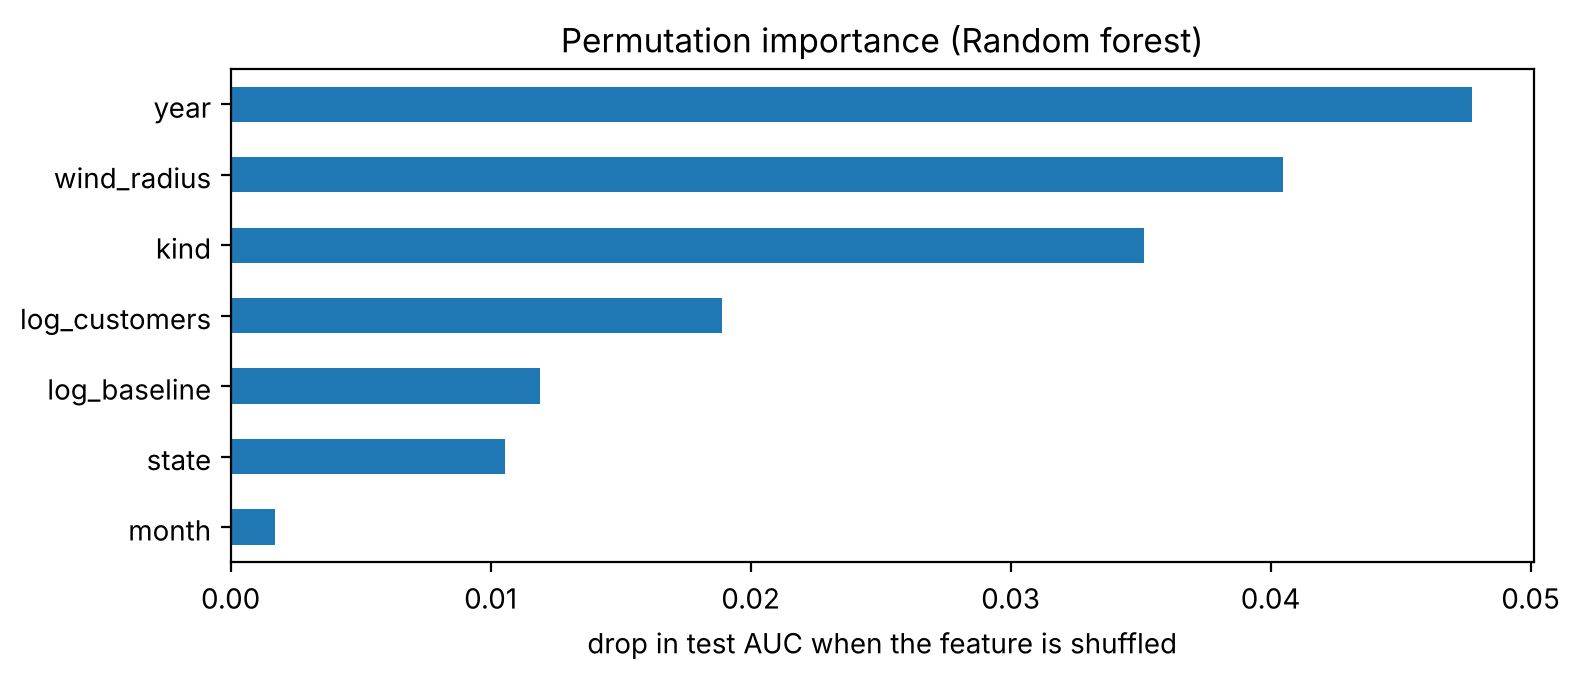

year             0.048
wind_radius      0.040
kind             0.035
log_customers    0.019
log_baseline     0.012
state            0.011
month            0.002
dtype: float64

In [20]:
imp = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
ax = imp.plot.barh(figsize=(8, 3.5))
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title(f'Permutation importance ({best_name})')
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

A shallow decision tree gives a picture of the same kind of rules. It is weaker than the ensemble, but it can be
read from top to bottom (depth 3 only, for readability).

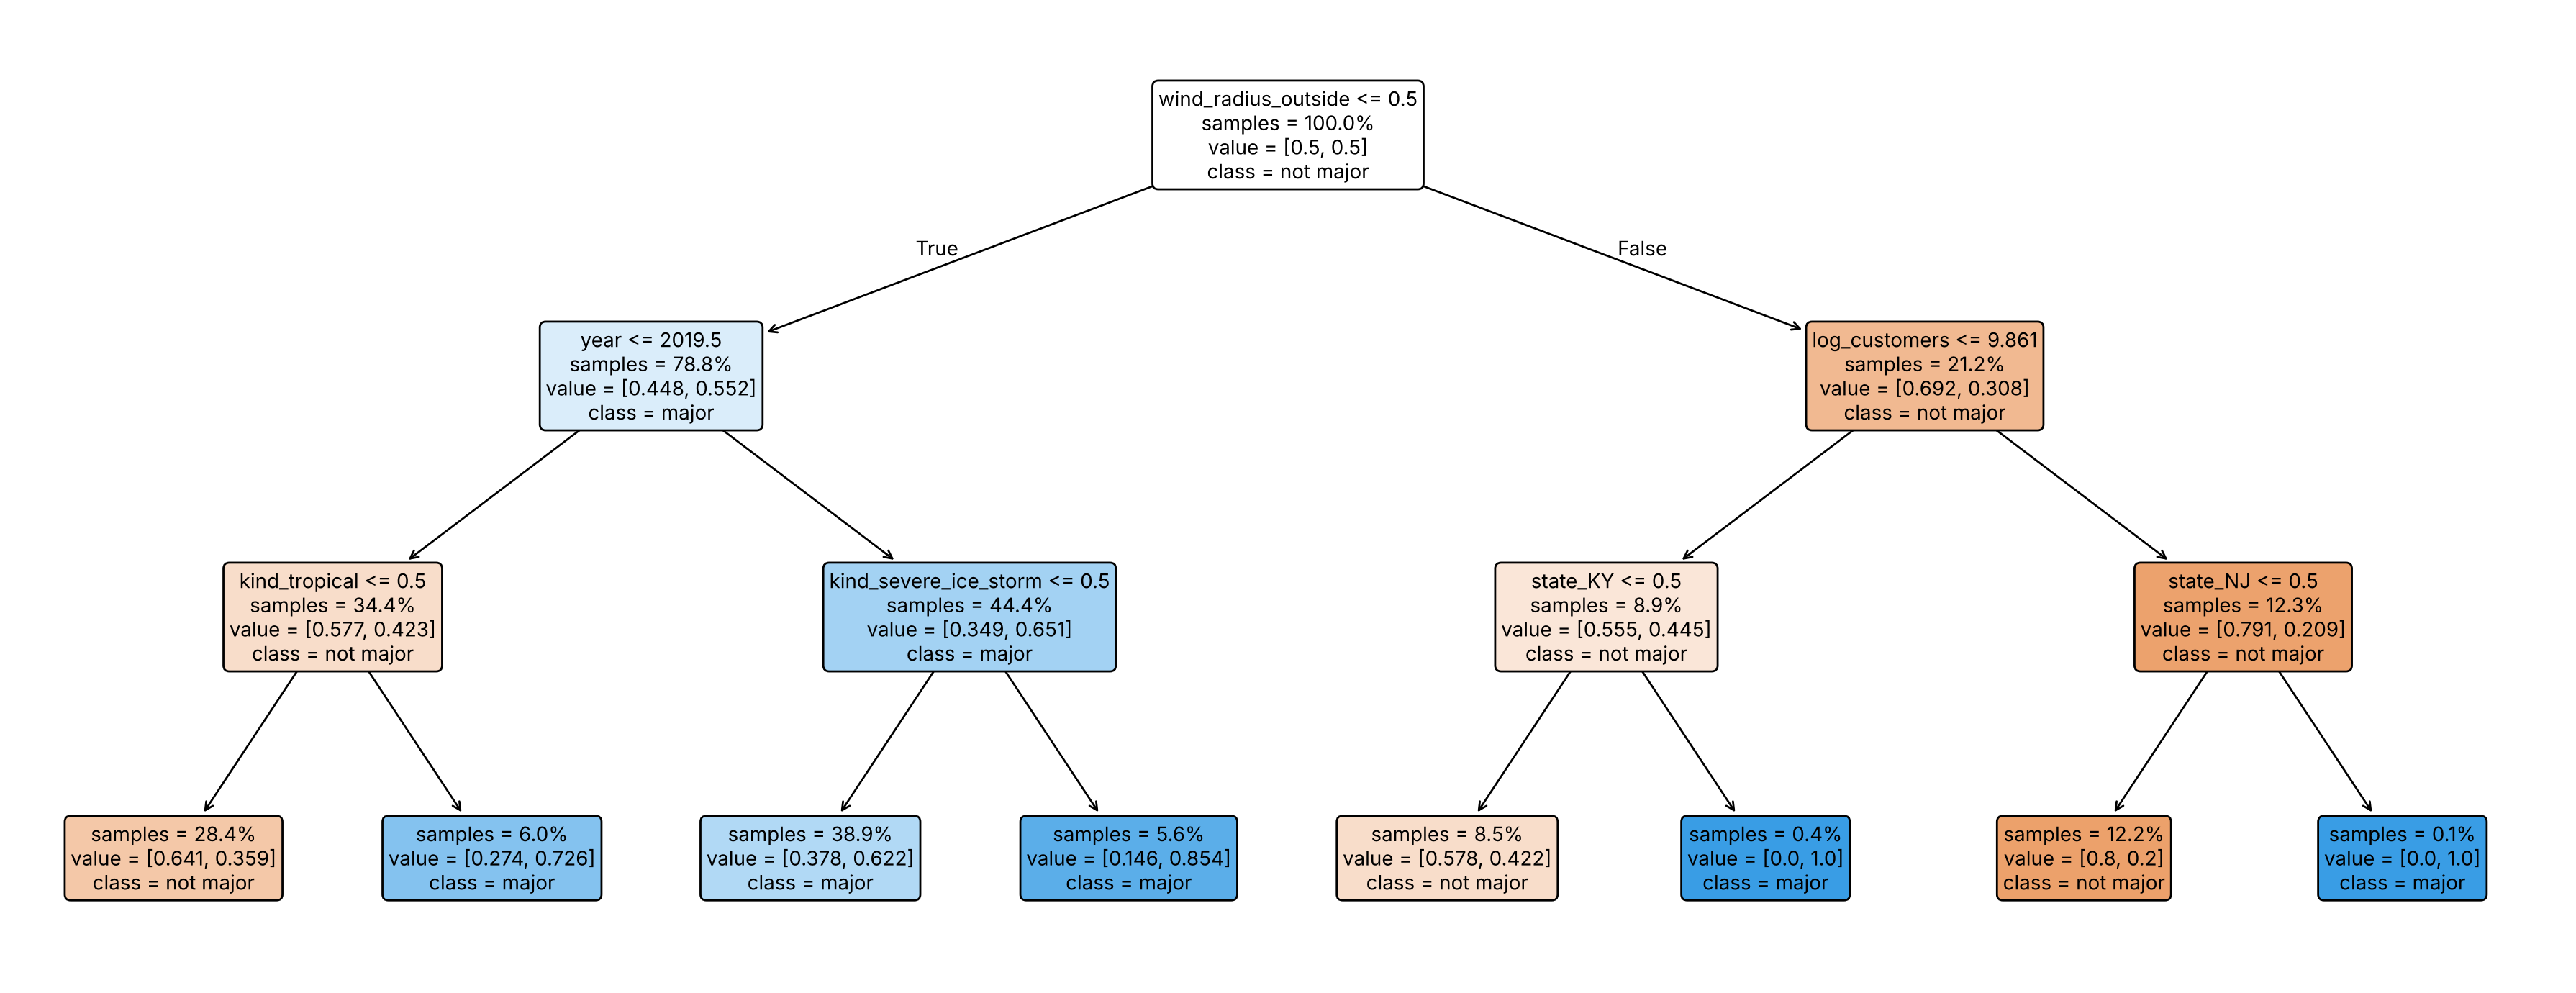

In [21]:
small_tree = onehot(DecisionTreeClassifier(max_depth=3, random_state=SEED), scale=False).fit(X_train, y_train)
names = small_tree[:-1].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(small_tree[-1], feature_names=[n.split('__', 1)[1] for n in names], class_names=['not major', 'major'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
plt.tight_layout(); plt.show()

## 8. Summary and next steps

In [22]:
summary = table['mean AUC'].round(3).to_dict()
print('Cross-validation split by storm (training storms):')
for k, v in sorted(summary.items(), key=lambda kv: kv[1]):
    print(f'  {k:30s} {v:.3f}')
print(f'\nFinal model ({best_name}) on unseen storms: AUC {roc_auc_score(y_test, proba):.3f}, accuracy {accuracy_score(y_test, pred):.3f}')

Cross-validation split by storm (training storms):
  Constant                       0.500
  Night light only (no model)    0.563
  Naive Bayes                    0.603
  Storm-type lookup table        0.607
  Decision tree (depth 5)        0.678
  Gradient boosting              0.698
  Logistic regression            0.706
  Random forest                  0.720

Final model (Random forest) on unseen storms: AUC 0.707, accuracy 0.668


- Night light alone barely beats a coin flip, as the dataset authors found.
- With a few features known at storm time, the best models (random forest, then logistic regression and gradient
  boosting) reach an AUC around 0.7 on storms they have never seen. This is better than every baseline, but far
  from perfect: county and storm descriptions only explain part of who loses power.
- The small tree splits first on the wind radius: counties known to be outside it rarely have a major outage.
- A random split would have overstated the score. Splitting by storm is necessary for an honest estimate.
- The wind radius is among the most useful features, but it only exists for Atlantic storms covered by HURDAT2.
  Adding real wind speed and pressure from HURDAT2 (future work) is the natural way to improve the model.
- The model's errors are not spread evenly: it does well on severe storms but misses most major outages in floods and
  snowstorms, and in hurricane counties outside the NHC wind radius (Ida). Lowering the threshold to 0.4 would catch
  85% of major outages instead of 71%, at the cost of more false alarms.
- Without the year the AUC drops by about 0.03, and training on the past (up to 2022) to predict the future (2023 on)
  gives 0.675: the year is a partial shortcut linked to data coverage, not the main source of the model's skill.
- Sending crews first to the 10% of counties with the highest predicted risk would hit a major outage 72% of the time,
  against 48% at random.

Next notebook: `03_regression`, the time needed to restore 90% of customers.